# Seed stability across all benchmark conditions

Results for all 36 benchmark conditions at 10, 15, 20 and 30 variables. Metrics are summarised within dataset instances before averaging across instances.


In [1]:
from pathlib import Path
import sys, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file())
sys.path.insert(0, str(ROOT / "analysis"))
from condition_data import load_results
import result_tables as th
import final_visualization as fv
fv.apply_style()
frame = th.prepare_metrics(load_results("benchmark"))
output = ROOT / "results/benchmark/by_condition"
output.mkdir(parents=True, exist_ok=True)


In [2]:
def plot_conditions(table, metric, title, filename, bounded=False):
    models = sorted(table.model.unique(), key=th.model_label)
    sizes = sorted(table.n_nodes.unique())
    fig, axes = plt.subplots(2, 2, figsize=(19, 14), constrained_layout=True)
    maximum = 1.0 if bounded else float(table[metric].max())
    cmap = plt.colormaps["viridis"].copy()
    cmap.set_bad("#e8e8e8")
    for ax, size in zip(axes.flat, sizes):
        selected = table.loc[table.n_nodes.eq(size)]
        matrix = selected.pivot(index="dataset", columns="model", values=metric).reindex(columns=models)
        image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy(float)), aspect="auto", cmap=cmap, vmin=0, vmax=maximum)
        labels = [textwrap.fill(name.split("nodes_", 1)[1].replace("_obsconf0_latconf0", "").replace("_", " "), 33) for name in matrix.index]
        ax.set_yticks(range(len(matrix)), labels, fontsize=8)
        ax.set_xticks(range(len(models)), [th.model_label(m) for m in models], rotation=55, ha="right", fontsize=8)
        ax.set_title(f"{int(size)} variables")
    fig.colorbar(image, ax=axes.ravel().tolist(), label=title, shrink=.7)
    fig.savefig(output / filename, bbox_inches="tight")
    display(fig)
    plt.close(fig)


,dataset,n_nodes,model,mean,std,size
0,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,AVICI,0.000000,0.000000,15
1,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Linear,0.000000,0.000000,15
2,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Nonlinear,0.513508,0.121925,15
3,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAS,0.000000,0.000000,15
4,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DirectLiNGAM,0.000000,0.000000,15
...,...,...,...,...,...,...
507,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,GraNDAG,0.000000,0.000000,15
508,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,NOTEARS,0.000000,0.000000,15
509,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,PC,0.000000,0.000000,15
510,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,Random,0.097471,0.018173,15


,dataset,n_nodes,model,mean,std,size
0,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,AVICI,0.404389,0.000000,15
1,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Linear,0.659722,0.000000,15
2,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Nonlinear,0.545753,0.137274,15
3,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAS,0.499316,0.000000,15
4,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DirectLiNGAM,0.524224,0.000000,15
...,...,...,...,...,...,...
507,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,GraNDAG,0.111111,0.000000,15
508,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,NOTEARS,0.185578,0.000000,15
509,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,PC,0.329060,0.000000,15
510,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,Random,0.088930,0.020979,15


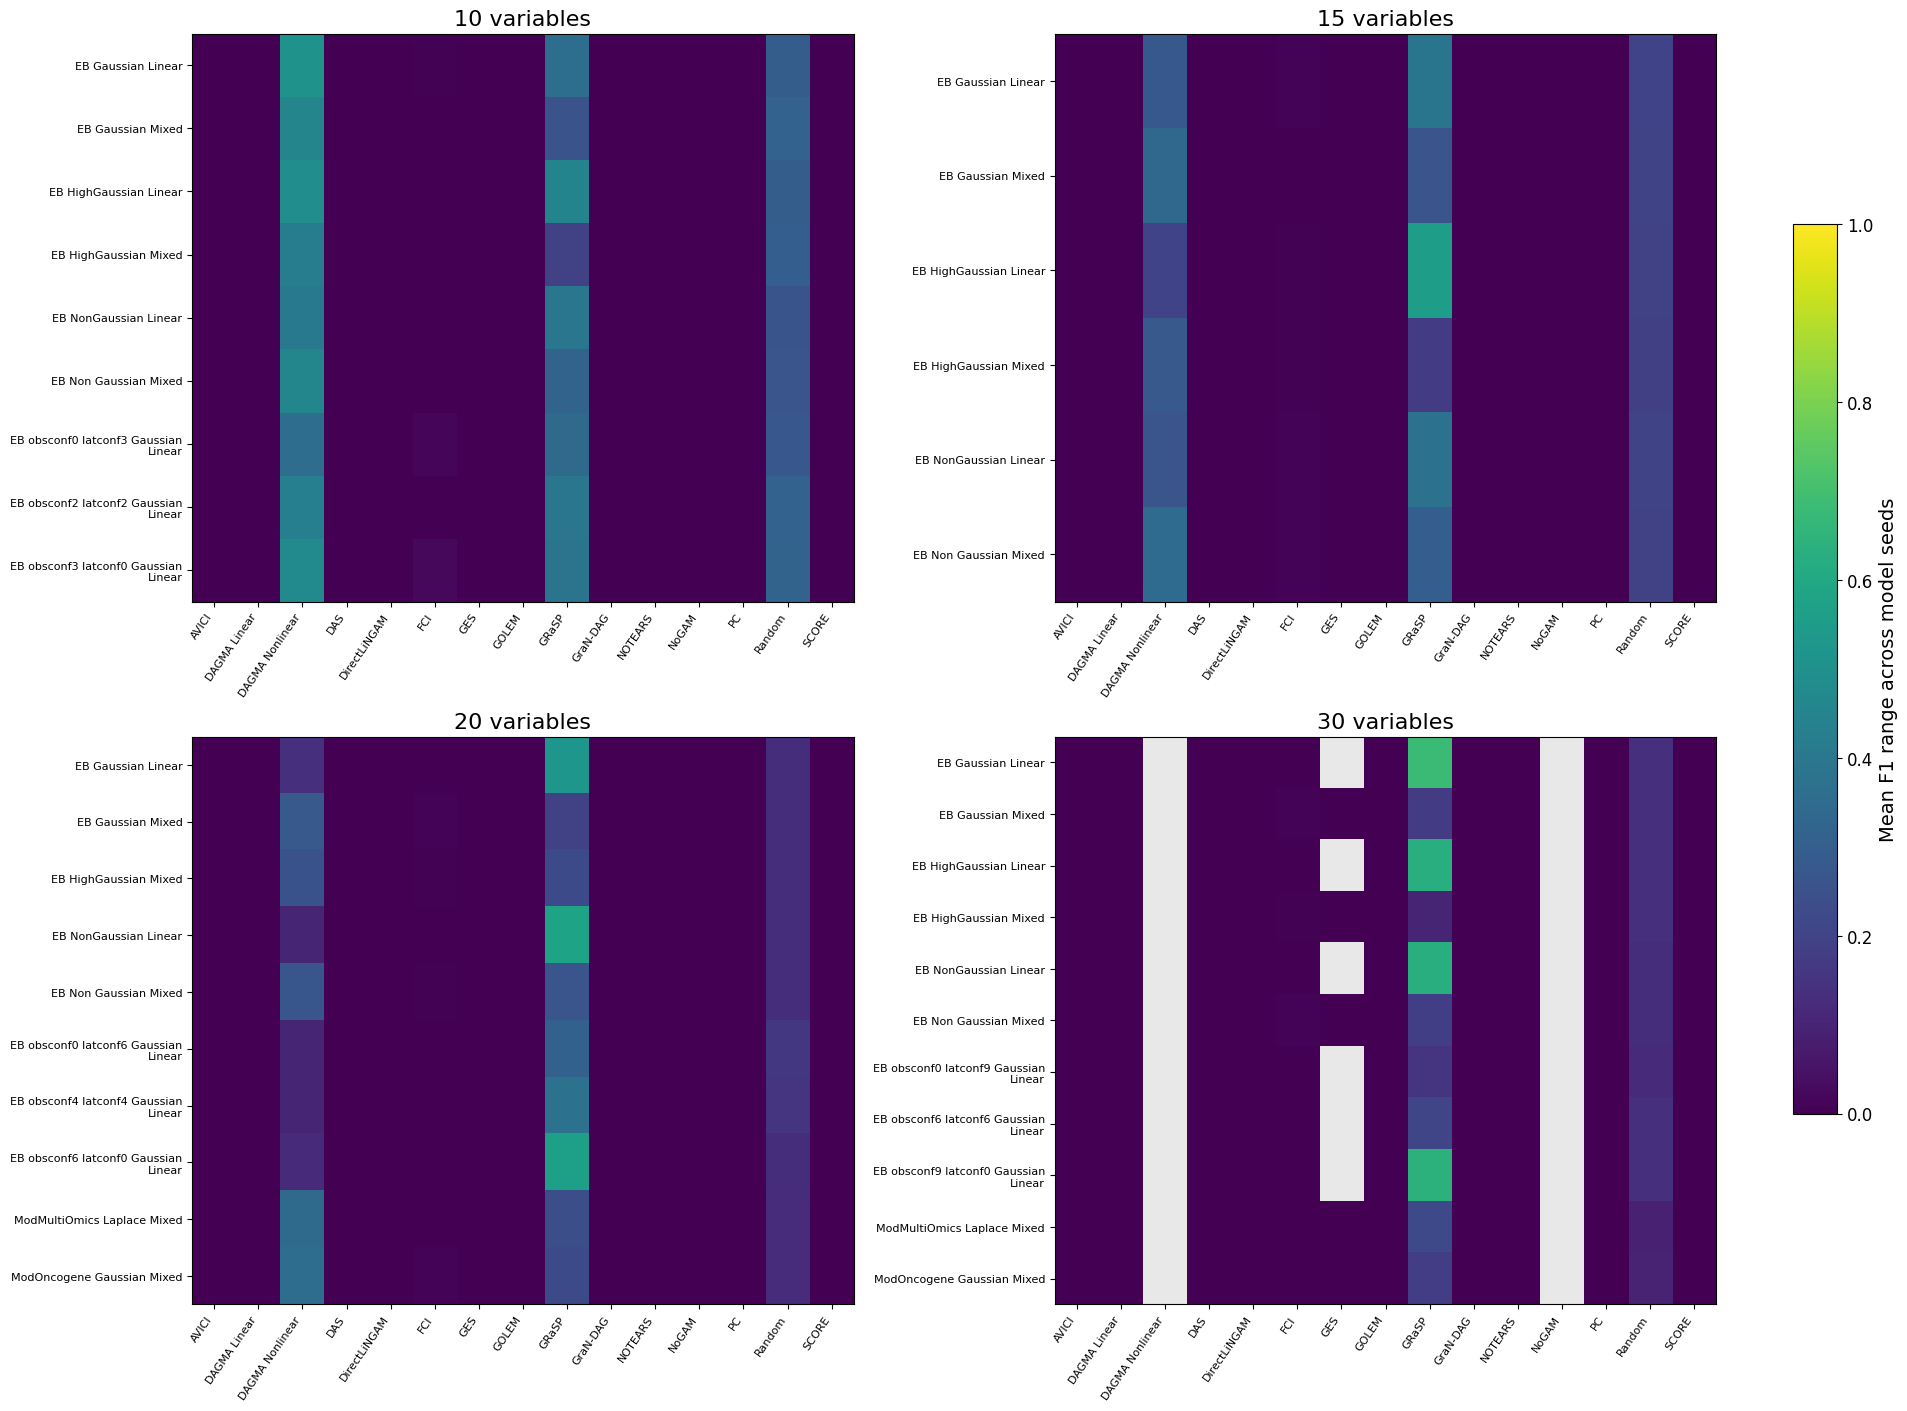

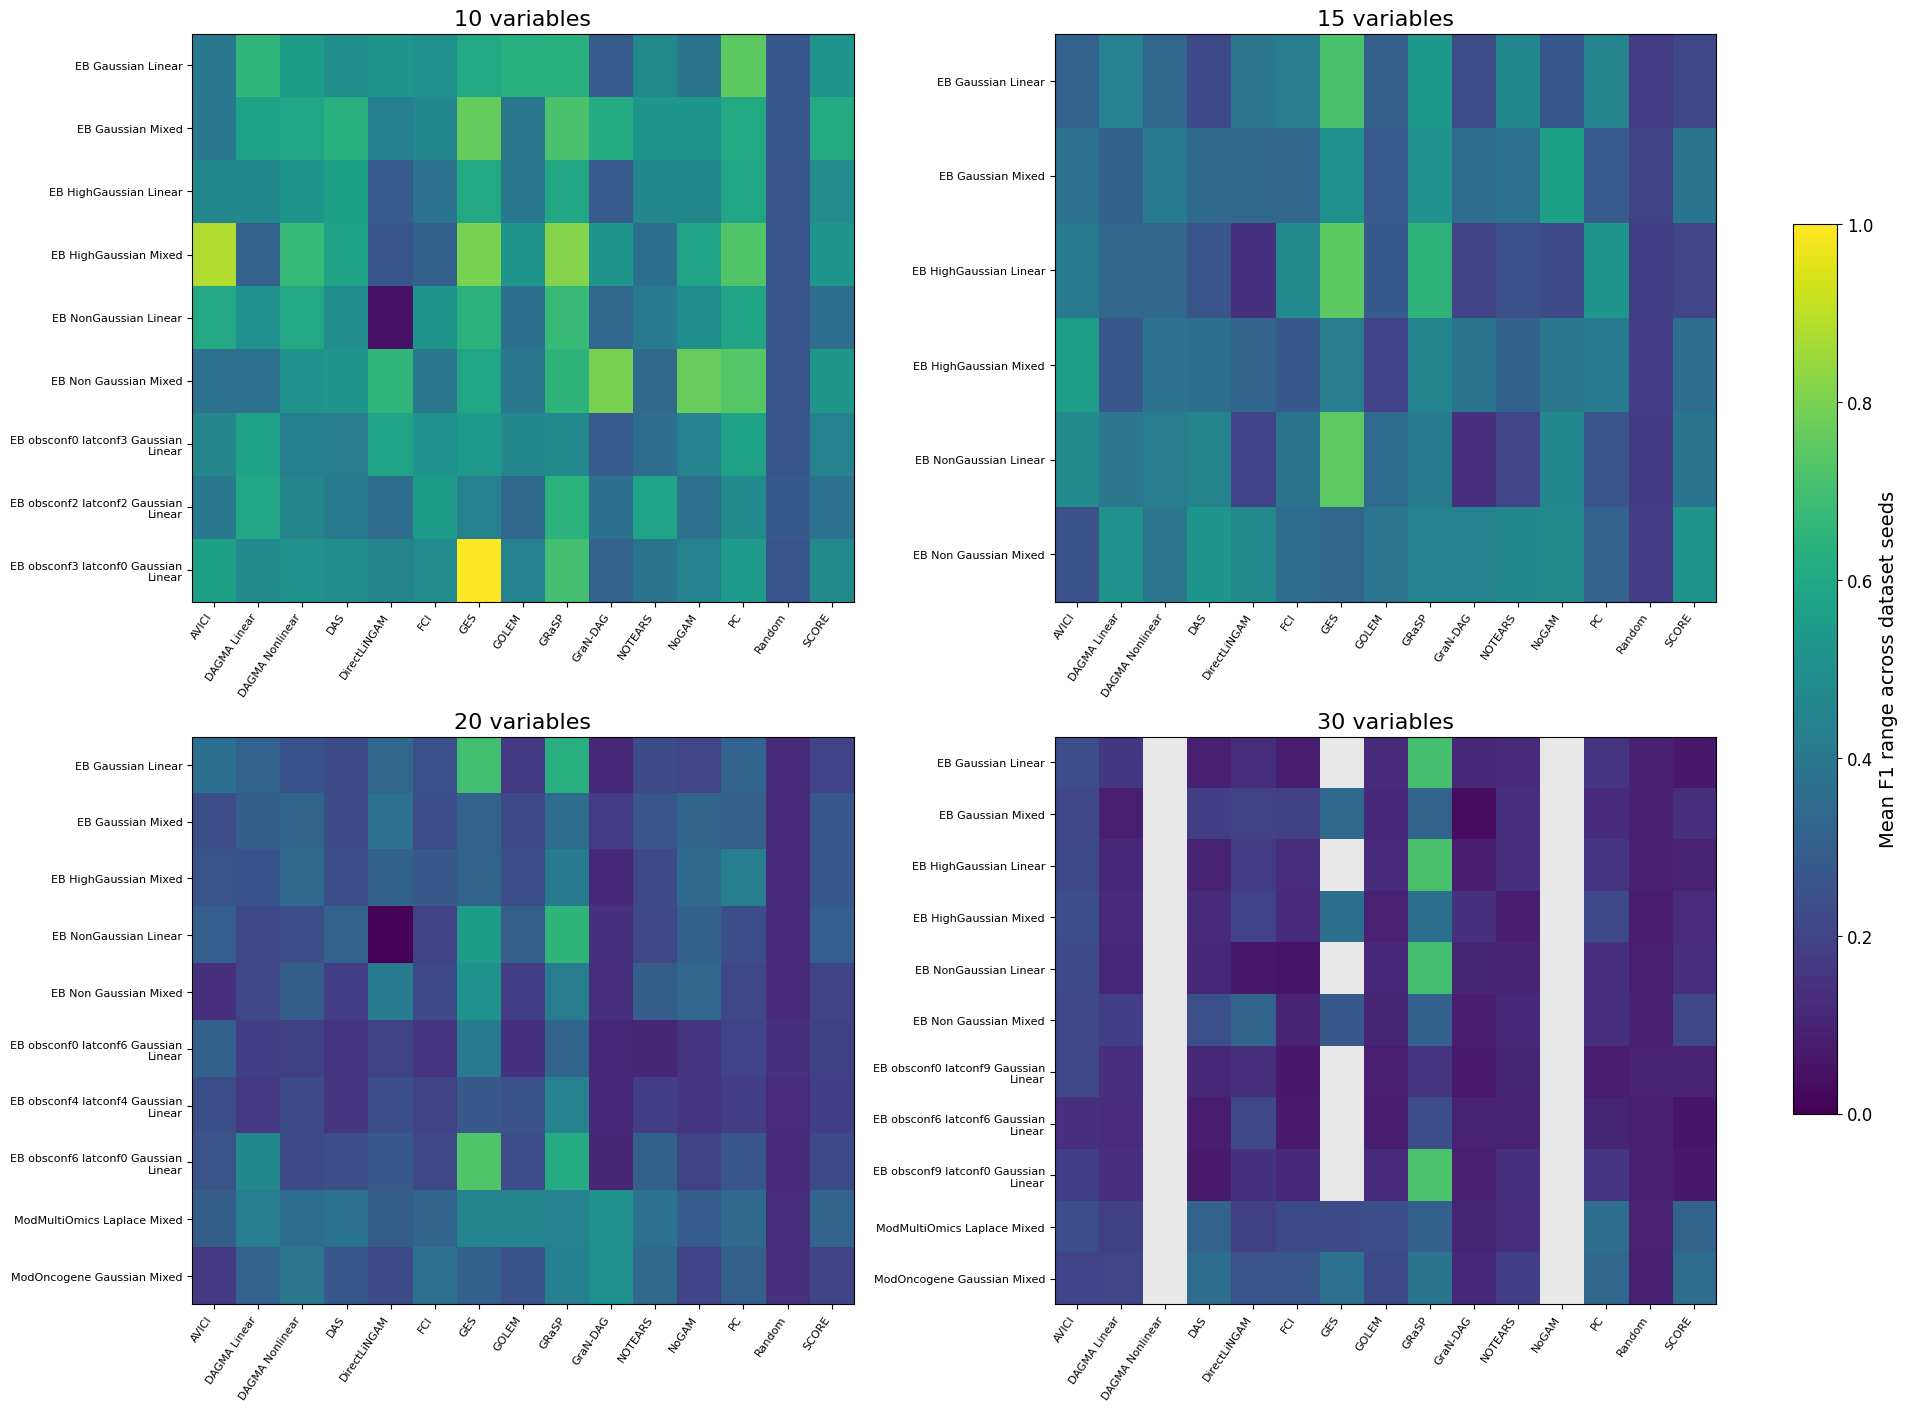

In [3]:
finished = frame.loc[frame.finished]
model_seed = finished.groupby(["dataset", "n_nodes", "dataset_seed", "model"], observed=True).f1.agg(lambda v: v.max()-v.min()).rename("f1_range").reset_index()
dataset_seed = finished.groupby(["dataset", "n_nodes", "model_seed", "model"], observed=True).f1.agg(lambda v: v.max()-v.min()).rename("f1_range").reset_index()
model_summary = model_seed.groupby(["dataset", "n_nodes", "model"], observed=True).f1_range.agg(["mean", "std", "size"]).reset_index()
dataset_summary = dataset_seed.groupby(["dataset", "n_nodes", "model"], observed=True).f1_range.agg(["mean", "std", "size"]).reset_index()
display(model_summary)
display(dataset_summary)
plot_conditions(model_summary, "mean", "Mean F1 range across model seeds", "model_seed_stability.pdf", bounded=True)
plot_conditions(dataset_summary, "mean", "Mean F1 range across dataset seeds", "dataset_seed_stability.pdf", bounded=True)
